## Before Running, Install
- pandas
- numpy
- matplotlib
- scikit-learn

## Framing the Problem

I'm helping retailer decide which customers to spend marketing budget on, and how to treat each group of customer differently. Purposes are to keep high value customers and win back the ones that are slipping away for so long.

## Our Workflow
- Data Audit
- Data cleaning
- EDA (seasonality + partial-December flag)
- RFM analysis
- Customer segmentation (rule-based labels)
- K-Means clustering (the modelling)
- Compare/validate segments → name them
- Recommendations 

## Load, Import and First Look

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('./online_retail_II.csv')

In [3]:
df.head(5)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  object 
 1   StockCode    1067371 non-null  object 
 2   Description  1062989 non-null  object 
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  object 
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 65.1+ MB


## Data Quality Audit

In [5]:
print("The dataset has {} rows and {} columns".format(df.shape[0], df.shape[1]))
print("The dataset has {} duplicate rows".format(df.duplicated().sum()))
print("The dataset's null values per column:")
print(df.isnull().sum())

The dataset has 1067371 rows and 8 columns
The dataset has 34335 duplicate rows
The dataset's null values per column:
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64


In [6]:
print(df.describe())

           Quantity         Price    Customer ID
count  1.067371e+06  1.067371e+06  824364.000000
mean   9.938898e+00  4.649388e+00   15324.638504
std    1.727058e+02  1.235531e+02    1697.464450
min   -8.099500e+04 -5.359436e+04   12346.000000
25%    1.000000e+00  1.250000e+00   13975.000000
50%    3.000000e+00  2.100000e+00   15255.000000
75%    1.000000e+01  4.150000e+00   16797.000000
max    8.099500e+04  3.897000e+04   18287.000000


### Converting InvoiceDate to DateTime

<Axes: xlabel='InvoiceDate'>

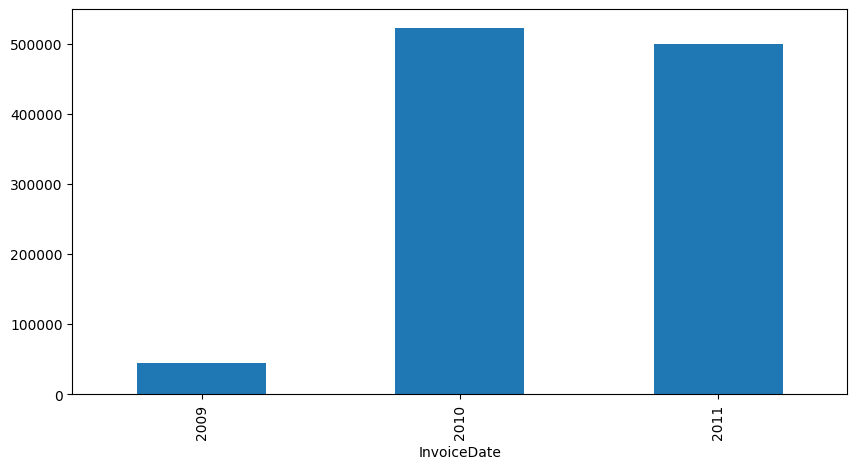

In [7]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['InvoiceDate'].dt.year.value_counts().sort_index().plot(kind='bar', figsize=(10, 5))

### Adding Year-Month Column

In [8]:
df['YearMonth'] = df['InvoiceDate'].dt.to_period('M')
coverage = df.groupby('YearMonth')['InvoiceDate'].agg(
    first='min', last='max',
    trading_days=lambda s: s.dt.normalize().nunique())
coverage

,first,last,trading_days
YearMonth,,,
2009-12,2009-12-01 07:45:00,2009-12-23 16:58:00,21
2010-01,2010-01-04 09:24:00,2010-01-31 16:02:00,24
2010-02,2010-02-01 08:13:00,2010-02-28 16:16:00,24
2010-03,2010-03-01 08:38:00,2010-03-31 17:53:00,27
2010-04,2010-04-01 07:49:00,2010-04-30 17:33:00,23
2010-05,2010-05-02 10:22:00,2010-05-30 15:58:00,24
2010-06,2010-06-01 09:02:00,2010-06-30 17:38:00,26
2010-07,2010-07-01 08:39:00,2010-07-30 17:08:00,26
2010-08,2010-08-01 10:04:00,2010-08-31 17:44:00,26


Most of the months have 20-27 trading days. December 2009 and December 2010 stop on 23rd because of Christmas break, but December 2011 stops on 9th with only 8 trading days, so it's a partial month. We will mark it in the trend charts, but the rows are still kept for RFM.

### Adding Partial Month to the DataFrame

In [9]:
PARTIAL_MONTH = pd.Period('2011-12', 'M')
df['is_partial_month'] = df['YearMonth'] == PARTIAL_MONTH
df.columns

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country', 'YearMonth', 'is_partial_month'],
      dtype='object')

### Checking Cancellations

In [10]:
is_cancel = df['Invoice'].astype(str).str.startswith('C')
print("There are {} cancelled line items and {} unique invoices".format(is_cancel.sum(), df.loc[is_cancel, 'Invoice'].nunique()))

There are 19494 cancelled line items and 8292 unique invoices


Unique invoices mean that one invoice from canceled order can contain many item, so we check it by distinct to know each invoice without having duplication.

### Checking Negative Quantity With No Cancel

In [11]:
is_neg_no_cancel = (df['Quantity'] < 0) & (~is_cancel)
print("There are {} negative quantity and {} unique invoices".format(is_neg_no_cancel.sum(), df.loc[is_neg_no_cancel, 'Invoice'].nunique()))
df[is_neg_no_cancel].head(5)

There are 3457 negative quantity and 3393 unique invoices


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,YearMonth,is_partial_month
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom,2009-12,False
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom,2009-12,False
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom,2009-12,False
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom,2009-12,False
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom,2009-12,False


### Checking Negative Quantity With Cancel

In [12]:
neg_cancel = (df['Quantity'] < 0) & (is_cancel)
print("There are {} negative quantity and {} unique invoices".format(neg_cancel.sum(), df.loc[neg_cancel, 'Invoice'].nunique()))

There are 19493 negative quantity and 8291 unique invoices


At first, we thought that quantity that has minus value on it is cancelled order. Proven that we're wrong because there are quantity that have minus value but order is not cancelled.

There is also one cancellation that does not have negative quantity, shown below.

In [13]:
# Cancelled but quantity is not negative
df[is_cancel & (df['Quantity'] >= 0)]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,YearMonth,is_partial_month
76799,C496350,M,Manual,1,2010-02-01 08:24:00,373.57,NaN,United Kingdom,2010-02,False


### Checking Negative Price

In [14]:
df[df['Price'] < 0].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,YearMonth,is_partial_month
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom,2010-04,False
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom,2010-07,False
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom,2010-10,False
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom,2011-08,False
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom,2011-08,False


- Found that the invoice code starts with A.
- Beside that, there's description says `Adjust bad debt`.
- Also, minus price value is so high.
- `Customer ID` NaN.
- StockCode unusual `'B'`

### Checking Zero Price

In [15]:
print((df['Price'] == 0).sum())
df[df['Price'] == 0].head(10)

6202


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,YearMonth,is_partial_month
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom,2009-12,False
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom,2009-12,False
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom,2009-12,False
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom,2009-12,False
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom,2009-12,False
3161,489659,21350,NaN,230,2009-12-01 17:39:00,0.0,NaN,United Kingdom,2009-12,False
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN,United Kingdom,2009-12,False
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN,United Kingdom,2009-12,False
3731,489781,84292,NaN,17,2009-12-02 11:45:00,0.0,NaN,United Kingdom,2009-12,False
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom,2009-12,False


There are 6202 rows (0.58%) with price 0, so they don't give any revenue. From the first rows, they have no Customer ID and the descriptions are like `lost`, `damages` or empty, similar with negative quantity with no cancel. Some of them have positive quantity too.

### Checking Invoice

In [16]:
df['Invoice'].astype(str).str.extract(r'^(\D*)')[0].value_counts()

0
     1047871
C      19494
A          6
Name: count, dtype: int64

There are only three types of invoice: plain numbers (normal sales), starts with `C` (cancellations, 19494 rows) and starts with `A` (6 rows, `Adjust bad debt`). 5 of the `A` rows have negative price. The sixth one (A563185) has positive price 11062.06 and it's entered one minute before two negative rows with the same amount.

### Checking StockCode

In [17]:
odd = df[~df['StockCode'].astype(str).str.match(r'^\d{5}[A-Za-z]*$')]
pd.set_option('display.max_rows', 100)
odd.groupby('StockCode')['Description'].agg(first='first', rows='size').sort_values('rows', ascending=False)

,first,rows
StockCode,,
POST,POSTAGE,2122
DOT,DOTCOM POSTAGE,1446
M,Manual,1421
C2,CARRIAGE,282
D,Discount,177
S,SAMPLES,104
BANK CHARGES,Bank Charges,102
ADJUST,Adjustment by john on 26/01/2010 16,67
AMAZONFEE,AMAZON FEE,43


The stockcode is not only for item but also for other operations

### Checking Outliers

In [18]:
df.nlargest(5, 'Quantity')

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,YearMonth,is_partial_month
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom,2011-12,True
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom,2011-01,False
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,2010-02-15 11:57:00,0.10,13902.0,Denmark,2010-02,False
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,2010-03-17 13:09:00,0.10,13902.0,Denmark,2010-03,False
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,2010-03-17 13:09:00,0.10,13902.0,Denmark,2010-03,False


The two top rows really stand apart than the third one. After `[80k+, 74k+]`, the next largest is `[19k+]`

In [19]:
df.nlargest(5, 'Price')

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,YearMonth,is_partial_month
748142,C556445,M,Manual,-1,2011-06-10 15:31:00,38970.00,15098.0,United Kingdom,2011-06,False
241824,C512770,M,Manual,-1,2010-06-17 16:52:00,25111.09,17399.0,United Kingdom,2010-06,False
241827,512771,M,Manual,1,2010-06-17 16:53:00,25111.09,NaN,United Kingdom,2010-06,False
320581,C520667,BANK CHARGES,Bank Charges,-1,2010-08-27 13:42:00,18910.69,NaN,United Kingdom,2010-08,False
1050063,C580605,AMAZONFEE,AMAZON FEE,-1,2011-12-05 11:36:00,17836.46,NaN,United Kingdom,2011-12,True


We can see that none of the top 5 is even a product, some have `'M'`, some have `'BANK CHARGES'`. Beside that, most of the rows are cancellations with quantity -1 and have no `'Customer ID'`. `'AMAZONFEE'` mean that the retail also sells in Amazon.

In [20]:
df[df['Quantity'].abs().isin([80995, 74215])]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,YearMonth,is_partial_month
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom,2011-01,False
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346.0,United Kingdom,2011-01,False
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom,2011-12,True
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,United Kingdom,2011-12,True


In [21]:
df[df['Quantity'] < 0].nsmallest(5, 'Quantity')

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,YearMonth,is_partial_month
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,United Kingdom,2011-12,True
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346.0,United Kingdom,2011-01,False
303996,519017,22759,NaN,-9600,2010-08-13 09:14:00,0.00,NaN,United Kingdom,2010-08,False
750990,556690,23005,printing smudges/thrown away,-9600,2011-06-14 10:37:00,0.00,NaN,United Kingdom,2011-06,False
750991,556691,23005,printing smudges/thrown away,-9600,2011-06-14 10:37:00,0.00,NaN,United Kingdom,2011-06,False


After checking highest in negative form, we found that the two highest value in positive form are actually refunded. So top two orders are refunded.

In [22]:
is_a_invoice = df['Invoice'].astype(str).str.startswith('A')
issues = {
    'missing_customer_id': df['Customer ID'].isna(),
    'missing_description': df['Description'].isna(),
    'duplicate_rows': df.duplicated(),
    'cancellation': is_cancel,
    'neg_qty_not_cancel': is_neg_no_cancel,
    'price_negative': df['Price'] < 0,
    'price_zero': df['Price'] == 0,
    'a_invoice': is_a_invoice,
    'non_product_code': df.index.isin(odd.index),
    'partial_month': df['is_partial_month'],
}
audit = pd.DataFrame({
    'rows': {k: int(v.sum()) for k, v in issues.items()},
    'pct': {k: round(v.mean() * 100, 2) for k, v in issues.items()},
})
audit

,rows,pct
missing_customer_id,243007,22.77
missing_description,4382,0.41
duplicate_rows,34335,3.22
cancellation,19494,1.83
neg_qty_not_cancel,3457,0.32
price_negative,5,0.00
price_zero,6202,0.58
a_invoice,6,0.00
non_product_code,6094,0.57
partial_month,25526,2.39


### Audit Summary
These are things that need to give attention about (counts from the audit table above):
- Description (column) has 4382 null rows
- CustomerID (column) has 243007 null rows
- It has 34,335 duplicates, non-product code 6,094, price 0 about 6,202, and partial-month 25,526.
- Price and Quantity have minimum value that are minus :
  - Cancellations (Invoices that start with C): All but one have negative quantity. The exception is a single "Manual" (StockCode M) entry with quantity +1, price 373.57 and no Customer ID, which is a manual accounting correction rather than a product return.
  - Negative without Cancellation: Descriptions are like "lost", "damages", etc and have no customer ID. It might be internal adjustments.
  - Negative Price: All of them have "A" on their invoice and have no customer ID, which means that it's an accounting write off from unpaid debt. There are 6 "A" invoices, the sixth one (A563185) has positive price and is entered right before two negative ones with the same amount.
- The top two rows that have huge gap from first two rows (80995, 74215) to third row (19152), turns out those two rows are cancelled orders.
- One Danish customer (13902) appears in several of the largest-quantity lines, mostly from a single invoice (501534): bulk paper cups/plates at £0.10 per unit. This looks like a wholesale-type buyer (not confirmed). Such buyers can skew averages and RFM scores.

## Data Cleaning

The plan is that we're gonna make 3 tables, such as:
- `sales`, contains real product sales. Might be used for products, time, and countries.
- `cust`, contains sales data but minus the rows that have no CustomerID. Might be used for RFM.
- `returns`, this is where we put out cancellations. Might be used for analysing returns.



Decision list :
- `Cancellations (C)` : Is gonna be excluded from sales and being kept in `returns`. It is because they are refunds and not purchases, leaving them would mixes negative lines into sales.
- `(A) Invoices (Bad debt)` : Drop. They are just an internal retail write-offs from accounting like unpaid debt, also have no Customer ID and large negative value that can disturb the revenue of sales.
- `Negative QTY, not cancelled` : Drop. They are unnecessary internal stock adjustments with descriptions like "lost","damages" and even price 0 with no customerID.
- `Price <= 0` : Drop. Row that has no price value can't be counted as sale.
- `Non Product StockCodes` : Drop. Codes like postage, carriage,discounts are fees and adjustment to price, not a products. It can break the sales revenue and product statistics.
- `Exact Duplicates` : Drop. Most of them (22,844 of 34,335) come from 1–9 December 2010, which appears twice in the file. The rest are identical lines that add no information. They are also dropped from `returns`, otherwise some refunds are counted twice.
- `Bulk orders that is cancelled (80k+, 74k+)` : Drop. We should make it as no sale happened because it's cancelled.
- `Order reversed by a Manual credit (invoice 556444)` : Drop. This £38,970 order from customer 15098 was cancelled 3 minutes later with a Manual credit (C556445), not a normal product cancellation, so the filters above don't catch it.
- `Missing Description` : Check while do the cleaning. The result is that 0 were left after the other cleaning steps.
- `Missing CustomerID` : Keep. It is still a sales data, they can count for product, time, and location analysis. RFM is per customer.
- `Partial Month` : Keep. It is a real row.

### Handle Cancellations, Negative QTY (not cancelled), and Price <= 0

In [23]:
# Drop A invoices too, A563185 has positive price
sales = df[~is_cancel & ~is_a_invoice & ~is_neg_no_cancel & (df['Price'] > 0) & (df['Quantity'] > 0)].copy()

### Handle Duplicates

In [24]:
print(sales.duplicated().sum())
sales.drop_duplicates(inplace=True)
print(sales.duplicated().sum())

33757
0


From the data audit, we got 34335 but now we found 33757. It is because 500+ duplicates had already been removed from the first filter.

### Where Do the Duplicates Come From?

In [25]:
# Duplicates per day
dup_per_day = df[df.duplicated()]['InvoiceDate'].dt.date.value_counts().sort_index()
dup_per_day[dup_per_day > 500]

InvoiceDate
2010-12-01    3152
2010-12-02    2150
2010-12-03    2219
2010-12-05    2830
2010-12-06    3926
2010-12-07    2980
2010-12-08    2686
2010-12-09    2901
Name: count, dtype: int64

In [26]:
# Rows per day before and after dedup, early Dec 2010
day = df['InvoiceDate'].dt.date
dedup = df.drop_duplicates()
per_day = pd.DataFrame({'raw_rows': df.groupby(day).size(),
                        'after_dedup': dedup.groupby(dedup['InvoiceDate'].dt.date).size()})
per_day.loc[pd.Timestamp('2010-11-29').date():pd.Timestamp('2010-12-13').date()]

,raw_rows,after_dedup
InvoiceDate,,
2010-11-29,3951,3921
2010-11-30,2416,2385
2010-12-01,6216,3064
2010-12-02,4218,2068
2010-12-03,4404,2185
2010-12-05,5450,2620
2010-12-06,7756,3830
2010-12-07,5926,2946
2010-12-08,5294,2608


Almost all duplicates are on 1–9 December 2010. On those days the number of rows is about double compared to after removing duplicates, while the days around them barely change. So these 9 days were loaded twice into the file. A likely reason is that the dataset joins two yearly sheets that overlap (this needs verification on the UCI dataset page). Removing exact duplicates fixes it. It also means any count done on the raw `df` (like the audit table) double-counts these days.

### Handle Bulk and Cancelled Orders

In [27]:
# Drop the top two rows bulk orders
sales = sales[~sales['Quantity'].isin([80995, 74215])]
sales.nlargest(5, 'Quantity')

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,YearMonth,is_partial_month
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,2010-02-15 11:57:00,0.1,13902.0,Denmark,2010-02,False
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,2010-03-17 13:09:00,0.1,13902.0,Denmark,2010-03,False
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,2010-03-17 13:09:00,0.1,13902.0,Denmark,2010-03,False
127169,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,2010-03-17 13:09:00,0.1,13902.0,Denmark,2010-03,False
127167,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,2010-03-17 13:09:00,0.1,13902.0,Denmark,2010-03,False


As we can see, the top quantity is 19,152.

### Handle Order Reversed by a Manual Credit (Customer 15098)

In [28]:
# All transactions from customer 15098
df[df['Customer ID'] == 15098][['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price']]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price
748131,556442,22502,PICNIC BASKET WICKER SMALL,60,2011-06-10 15:22:00,4.95
748132,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,2011-06-10 15:28:00,649.50
748142,C556445,M,Manual,-1,2011-06-10 15:31:00,38970.00
748143,556446,22502,PICNIC BASKET WICKER 60 PIECES,1,2011-06-10 15:33:00,649.50
748153,C556448,22502,PICNIC BASKET WICKER SMALL,-60,2011-06-10 15:39:00,4.95


Order 556444 (60 × £649.50 = £38,970) was cancelled three minutes later with a Manual credit C556445 of exactly £38,970. Because the credit uses StockCode `M` instead of the product code, our cancellation filter keeps the original order in `sales`, and this customer would look like one of the top spenders.

Invoice 556446 (1 × £649.50) looks like the corrected re-entry of the same order, so it is kept. This is an interpretation, not confirmed by the data.

In [29]:
# Drop 556444 only, 556446 is the corrected one
before = len(sales)
sales = sales[sales['Invoice'].astype(str) != '556444']
print("rows dropped:", before - len(sales))

rows dropped: 1


### Handle Non-Product StockCodes

In [30]:
NON_PRODUCT = {'POST', 'DOT', 'M', 'm', 'C2', 'C3', 'D', 'S', 'B', 'BANK CHARGES',
               'ADJUST', 'ADJUST2', 'AMAZONFEE', 'CRUK', 'TEST001', 'TEST002'}
code = sales['StockCode'].astype(str)
is_non_product = code.isin(NON_PRODUCT) | code.str.startswith('gift_')
print(is_non_product.sum())
sales = sales[~is_non_product].copy()

4555


If we notice, it is more smaller amount than the audit one. Many rows were already gone because of cancellations and zero price rows.

### Check Missing Description

In [31]:
print(sales['Description'].isna().sum())

0


### Build Revenue, `returns` and `cust`

In [32]:
sales['Revenue'] = sales['Quantity'] * sales['Price']
returns = df[is_cancel].drop_duplicates().copy()
cust = sales[sales['Customer ID'].notna()].copy()
cust['Customer ID'] = cust['Customer ID'].astype(int).astype(str)

In [33]:
print("raw rows:", len(df))
print("sales rows:", len(sales))
print("cust rows (with Customer ID):", len(cust))
print("returns rows:", len(returns))

raw rows: 1067371
sales rows: 1003354
cust rows (with Customer ID): 776593
returns rows: 19104


In [34]:
sales.columns.tolist()

['Invoice',
 'StockCode',
 'Description',
 'Quantity',
 'InvoiceDate',
 'Price',
 'Customer ID',
 'Country',
 'YearMonth',
 'is_partial_month',
 'Revenue']

After done cleaning, `sales` keeps 1,003,354 of 1,067,371 rows, so that's about 94%. `cust` has 776,593 rows, which is about 73% of the raw data (77% of `sales`). `returns` has 19,104 rows after removing duplicates.

## EDA

### 1. Sales Over Time

#### Revenue per Month

In [35]:
revenue_per_month = sales.groupby('YearMonth')['Revenue'].sum()
revenue_per_month.head()

YearMonth
2009-12    797901.160
2010-01    612297.422
2010-02    537909.676
2010-03    761705.981
2010-04    646340.932
Freq: M, Name: Revenue, dtype: float64

<Axes: title={'center': 'Revenue per month (grey = partial month, data ends 9 Dec 2011)'}, xlabel='YearMonth', ylabel='Revenue (£ million)'>

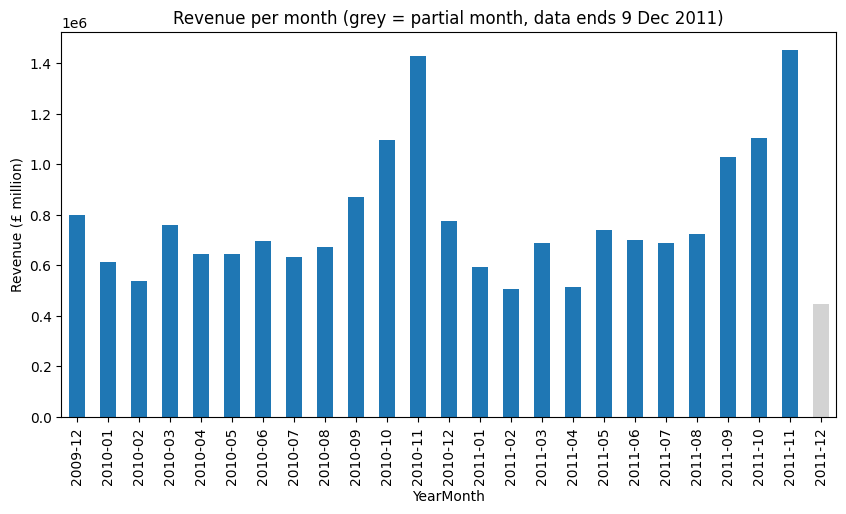

In [36]:
colors = ['lightgrey' if m == PARTIAL_MONTH else 'tab:blue' for m in revenue_per_month.index]
plt.ylabel('Revenue (£ million)')
revenue_per_month.plot(kind='bar', figsize=(10, 5), color=colors,
                       title='Revenue per month (grey = partial month, data ends 9 Dec 2011)')

#### Orders per Month

In [37]:
orders_per_month = sales.groupby('YearMonth')['Invoice'].nunique()
orders_per_month.head(5)

YearMonth
2009-12    1666
2010-01    1049
2010-02    1189
2010-03    1647
2010-04    1435
Freq: M, Name: Invoice, dtype: int64

<Axes: title={'center': 'Orders per month (grey = partial month, data ends 9 Dec 2011)'}, xlabel='YearMonth', ylabel='Number of Orders'>

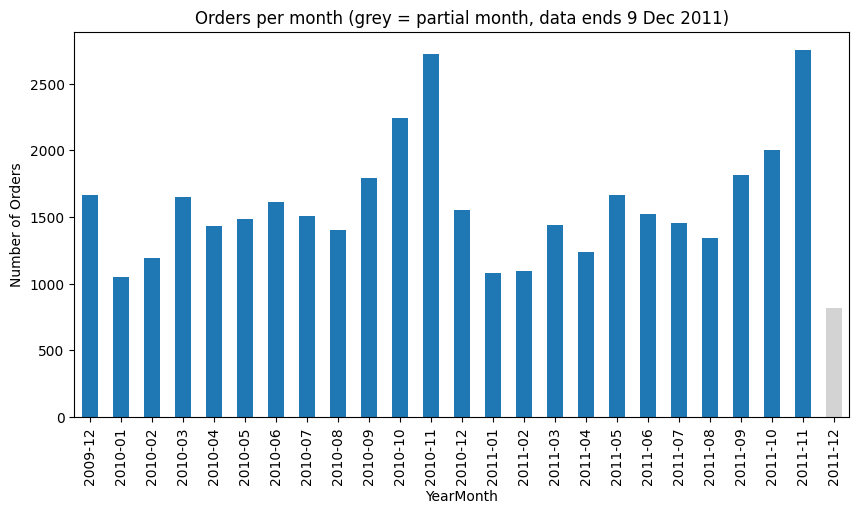

In [38]:
colors = ['lightgrey' if m == PARTIAL_MONTH else 'tab:blue' for m in orders_per_month.index]
plt.ylabel('Number of Orders')
orders_per_month.plot(kind='bar', figsize=(10, 5), color=colors,
                       title='Orders per month (grey = partial month, data ends 9 Dec 2011)')

#### Customers per Month

In [39]:
customers_per_month = cust.groupby('YearMonth')['Customer ID'].nunique()
customers_per_month.head(5)

YearMonth
2009-12     951
2010-01     701
2010-02     771
2010-03    1051
2010-04     939
Freq: M, Name: Customer ID, dtype: int64

<Axes: title={'center': 'Customers per month (grey = partial month, data ends 9 Dec 2011)'}, xlabel='YearMonth', ylabel='Number of Customers'>

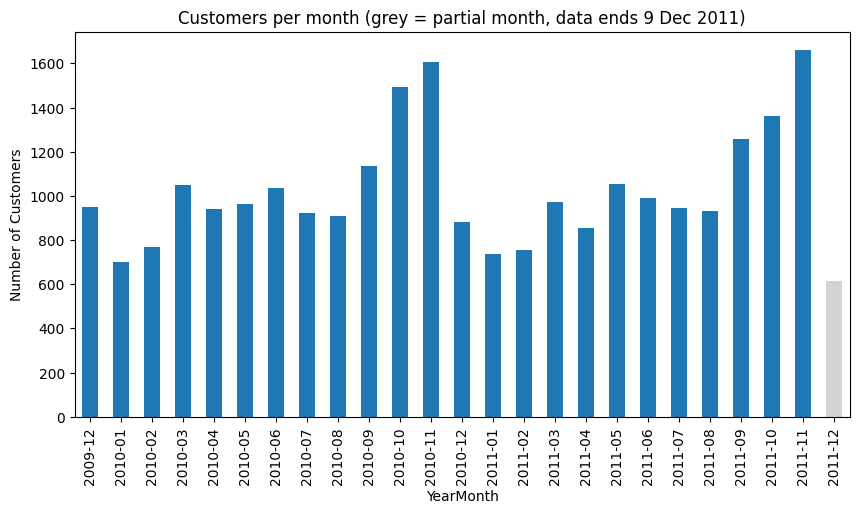

In [40]:
colors = ['lightgrey' if m == PARTIAL_MONTH else 'tab:blue' for m in customers_per_month.index]
plt.ylabel('Number of Customers')
customers_per_month.plot(kind='bar', figsize=(10, 5), color=colors,
                         title='Customers per month (grey = partial month, data ends 9 Dec 2011)')

In [41]:
# Jan-Nov only so both years are compared fairly
same_months = sales[sales['InvoiceDate'].dt.month <= 11]
same_months.groupby(same_months['InvoiceDate'].dt.year).agg(
    revenue=('Revenue', 'sum'), orders=('Invoice', 'nunique'))

,revenue,orders
InvoiceDate,,
2010,8598741.154,18077
2011,8740936.443,17405


<Axes: title={'center': 'Revenue per customer per month (grey = partial month)'}, xlabel='YearMonth', ylabel='Revenue per customer (£)'>

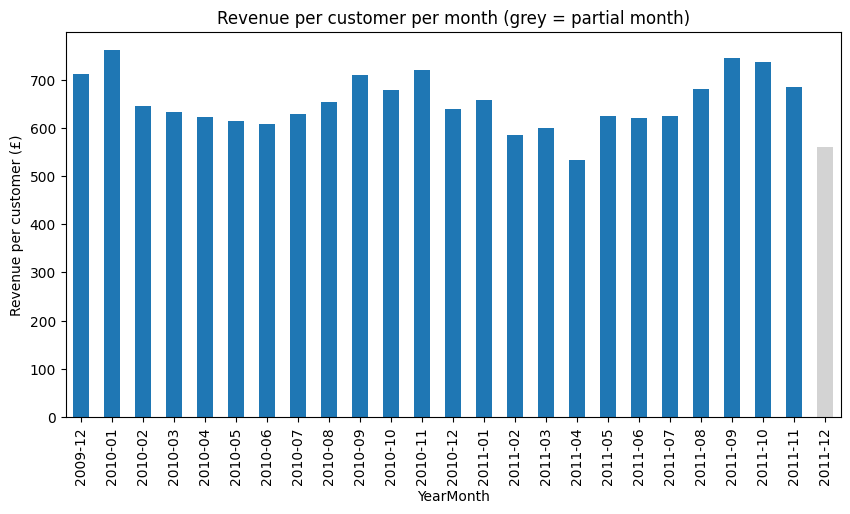

In [42]:
rev_per_customer = cust.groupby('YearMonth')['Revenue'].sum() / customers_per_month
colors = ['lightgrey' if m == PARTIAL_MONTH else 'tab:blue' for m in rev_per_customer.index]
plt.ylabel('Revenue per customer (£)')
rev_per_customer.plot(kind='bar', figsize=(10, 5), color=colors,
                      title='Revenue per customer per month (grey = partial month)')

#### Interpretation

From the charts above, we can see that the highest month is November in both years (Around £1.43M in 2010 and £1.45M in 2011), followed by October and September. Sales from January to August stay fairly flat at around £0.5M to £0.75M per month. After that, they start rising from September until November which is the peak.

December goes down because the shop is closing around 23 December, and for December 2011 (the grey one), it's low because the data stops on 9 December, so it's only the first 9 days. The same pattern happens in both years. Also, when we compare the same months between years, 2011 revenue is £8.74M against £8.60M in 2010 (Around 1.7% higher), but the number of orders went down by 3.7%. It makes 2011 flat, slightly fewer orders but bigger ones.

The revenue chart and customer chart have almost the same shape as we can see. From customer chart, the number go from around 750 a month in February to about 1,600 in November (It is about double), meanwhile revenue per customer only moves between £530 (Apr 2011) to £760 (Jan 2010). Revenue per customer is a bit higher in autumn, but that rise is small next to the doubling in customers, so the autumn rise comes mostly from more customers.

Sales are about the same year to year, with peak from September to November where the customers who buy are about twice as many as in February. By that, stock and campaigns should be ready by August, and beside that, we should try to get customers to come back in the quieter months.

### 2. New vs Returning Customers

#### Each Customer's First Purchase Month

In [43]:
new_customers = cust.groupby('Customer ID')['InvoiceDate'].min()
new_customers_per_month = new_customers.groupby(new_customers.dt.to_period('M')).size()
new_customers_per_month.head(10)

InvoiceDate
2009-12    951
2010-01    368
2010-02    375
2010-03    441
2010-04    294
2010-05    255
2010-06    267
2010-07    185
2010-08    163
2010-09    239
Freq: M, Name: InvoiceDate, dtype: int64

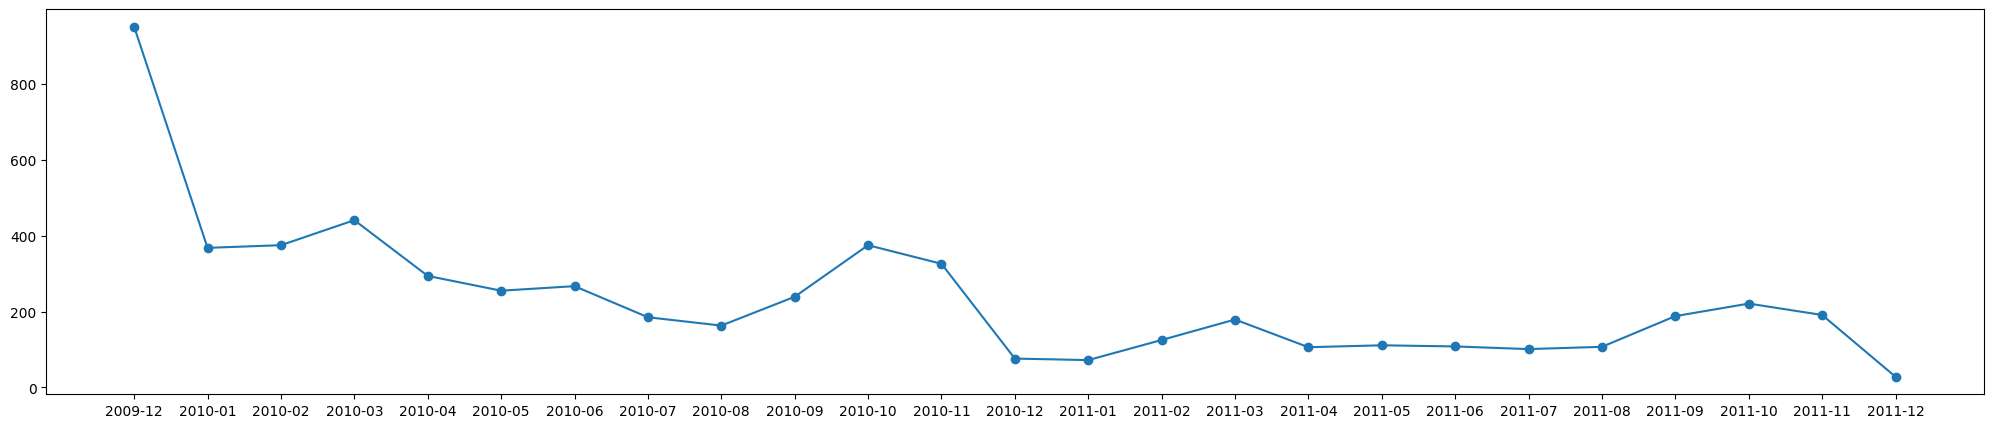

In [44]:
plt.figure(figsize=(25, 5))
plt.plot(new_customers_per_month.index.astype(str), new_customers_per_month.values, marker='o' )

#### Labeling Each Customer in Each Month

In [45]:
returning_customers_per_month = customers_per_month - new_customers_per_month
returning_customers_per_month

YearMonth
2009-12       0
2010-01     333
2010-02     396
2010-03     610
2010-04     645
2010-05     710
2010-06     767
2010-07     739
2010-08     747
2010-09     897
2010-10    1117
2010-11    1280
2010-12     808
2011-01     666
2011-02     632
2011-03     794
2011-04     747
2011-05     943
2011-06     882
2011-07     845
2011-08     826
2011-09    1071
2011-10    1140
2011-11    1469
2011-12     585
Freq: M, dtype: int64

Text(0, 0.5, 'Number of customers')

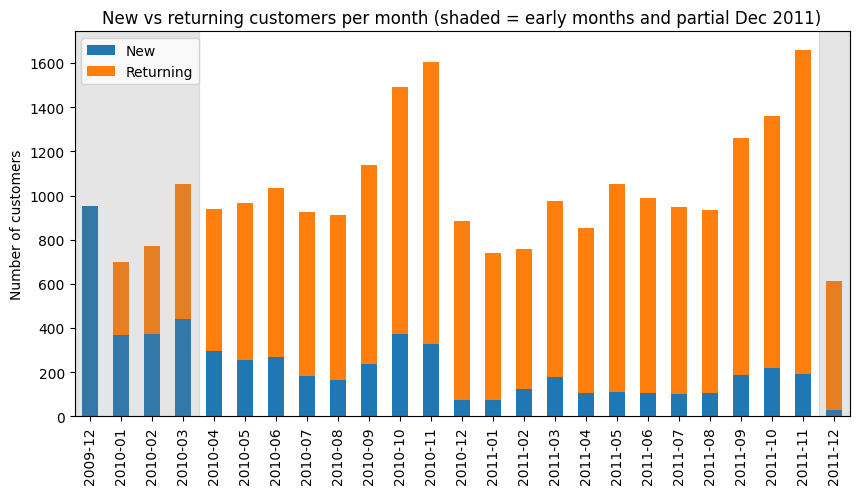

In [46]:
new_vs_returning = pd.DataFrame({'New': new_customers_per_month,
                                 'Returning': returning_customers_per_month})
ax = new_vs_returning.plot(kind='bar', stacked=True, figsize=(10, 5),
                           title='New vs returning customers per month (shaded = early months and partial Dec 2011)')
# Shade early months and Dec 2011
ax.axvspan(-0.5, 3.5, color='grey', alpha=0.2)
ax.axvspan(23.5, 24.5, color='grey', alpha=0.2)
ax.set_ylabel('Number of customers')

#### Counting One-Time Buyers

In [47]:
orders_per_customer = cust.groupby('Customer ID')['Invoice'].nunique()
print("customers:", len(orders_per_customer))
print("one-time buyers:", (orders_per_customer == 1).sum())
print("one-time %:", round((orders_per_customer == 1).mean() * 100, 1))

customers: 5852
one-time buyers: 1619
one-time %: 27.7


#### Interpretation

The spike of new customers in 2009-12 is because it's the first month in the dataset. Everyone counts as "new" since there's no earlier history, so it's because of the data window, not because the store just opened. Returning customers that month = 0 for the same reason. The next few months (until March 2010, shaded) still show too many new customers, so we don't take conclusion from them.

The number of new customers is going down over time. About 260 new customers a month joined in April-November 2010, compared to about 140 in the same months of 2011, so it's roughly 45% fewer. The peak is in October in both years. Even with fewer new customers, returning customers were about 77% of monthly buyers in Apr-Nov 2010 and about 87% in Jan-Nov 2011 (1,469 of 1,660 in Nov 2011), so the business depends more and more on returning customers. These are customer counts, not revenue.

Returning customers rise over each year and peak in November, 1,280 in 2010 and 1,469 in 2011. There are also one-time buyers, which is 27.7% of all customers (1,619 of 5,852), so about 1 in 4 never placed second order. A follow-up after the first order might be needed to turn more of them into returning customers. Part of this comes from customers who first bought in September-December 2011 and didn't have much time to come back, so the real share is a bit lower.

Nearly 9 of the 10 buyers each month are returning customers, but around half as many new customers joined in 2011 and 1 in 4 customers never ordered again. By that, we should follow up with every first-time buyer and run new-customer campaigns before the autumn peak.

### 3. Who Brings the Most Money

#### Spend Per Customer

In [48]:
spend = cust.groupby('Customer ID').agg(
    country=('Country', 'first'),
    orders=('Invoice', 'nunique'),
    spend=('Revenue', 'sum'))
spend['avg_order'] = spend['spend'] / spend['orders']

In [49]:
spend.head(5)

,country,orders,spend,avg_order
Customer ID,,,,
12346,United Kingdom,2,169.36,84.68000
12347,Iceland,8,4921.53,615.19125
12348,Finland,5,1658.40,331.68000
12349,Italy,3,3678.69,1226.23000
12350,Norway,1,294.40,294.40000


#### Spread

mean: 2868 median: 856


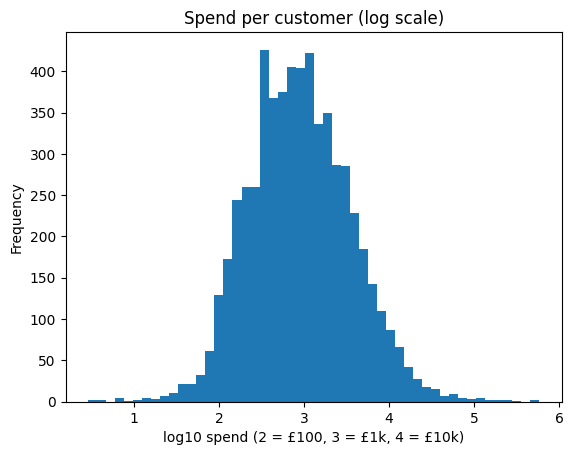

In [50]:
np.log10(spend['spend']).plot(kind='hist', bins=50, title='Spend per customer (log scale)')
plt.xlabel('log10 spend (2 = £100, 3 = £1k, 4 = £10k)')
print("mean:", round(spend['spend'].mean()), "median:", round(spend['spend'].median()))

#### Concentration

% of customers for 50% of revenue: 4.6
% of customers for 80% of revenue: 23.5


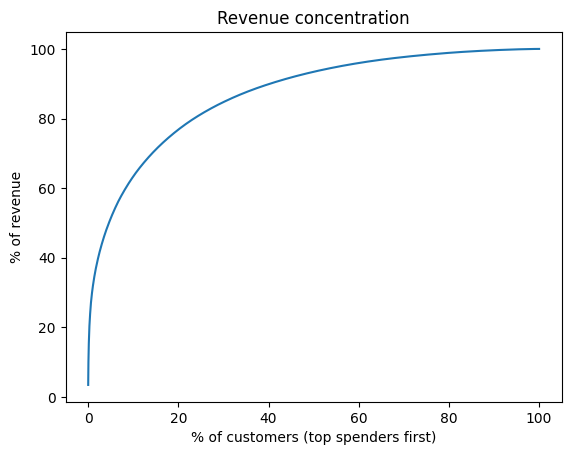

In [51]:
s = spend['spend'].sort_values(ascending=False)
cum_share = s.cumsum() / s.sum() * 100
cust_share = np.arange(1, len(s) + 1) / len(s) * 100
plt.plot(cust_share, cum_share)
plt.xlabel('% of customers (top spenders first)')
plt.ylabel('% of revenue')
plt.title('Revenue concentration')
print("% of customers for 50% of revenue:", round((cum_share < 50).mean() * 100, 1))
print("% of customers for 80% of revenue:", round((cum_share < 80).mean() * 100, 1))

#### Top 10 Customers

In [52]:
spend.sort_values('spend', ascending=False).head(10)

,country,orders,spend,avg_order
Customer ID,,,,
18102,United Kingdom,145,580987.04,4006.807172
14646,Netherlands,145,526751.52,3632.769103
14156,EIRE,144,303069.88,2104.651944
14911,EIRE,373,272252.79,729.900241
17450,United Kingdom,51,244784.25,4799.691176
13694,United Kingdom,143,195640.69,1368.116713
17511,United Kingdom,60,172132.87,2868.881167
16684,United Kingdom,55,147142.77,2675.323091
12415,Australia,24,144033.37,6001.390417


#### Interpretation

All of the numbers here only cover customers with a Customer ID, not all revenue. Sales without an ID are left out.

We used gross spend (purchases only). The refunds of the two reversed bulk orders and customer 15098's order are still in `returns`, but those sales were already removed in cleaning, so if we subtract `returns` the refunds will be counted twice.

The mean spend is £2,868, but the median is only £856, so the mean is more than 3 times the median and the spend is very skewed. Most of customers spend under £1,000, and only a small number of very big customers pull the average up. So the median describes a typical customer better than the mean, because it's robust to outliers.

Going deeper into revenue, we found that only 4.6% of customers (about 270 people) bring in 50% of the revenue, and 23.5% bring in 80%. It's close to the 80/20 rule, so losing a few top customers would hurt revenue much more than losing many small ones.

The top 10 are a mix of frequent buyers and few very big orders. Six of them placed 127-373 orders over two years, like customer 14911 (EIRE) who placed 373 orders at about £730 each. The other four are 12415 (Australia: 24 orders at about £6,000 each), 17450 (UK: 51 orders at about £4,800 each), and 17511 and 16684 (UK: 55-60 orders at about £2,700-£2,900 each), they buy less often but in very large amounts. All together, the top 10 brought about £2.7M, roughly 16% of identified revenue.

For K-Means, it groups customers by distance, so these few huge spenders will sit very far from everyone else. They can end up in their own cluster, pull a cluster centre to them, or push all the normal customers into one big group. The log scale helped the histogram because it shrinks the huge values and spreads out the normal ones, so we will log and scale the spend before clustering.

About 1 in 20 customers bring in half of the revenue. By that, we should keep our top customers happy first, for example with a personal contact and priority service.

### 4. Days Between Purchases

#### Gaps Between Orders

In [53]:
orders = cust.groupby(['Customer ID', 'Invoice'])['InvoiceDate'].min().reset_index()

orders['day'] = orders['InvoiceDate'].dt.normalize()
visits = orders.drop_duplicates(['Customer ID', 'day']).sort_values(['Customer ID', 'day']).copy()
print("orders:", len(orders))
print("visits (same-day orders merged):", len(visits))

orders: 36591
visits (same-day orders merged): 32876


In [54]:
visits['gap_days'] = visits.groupby('Customer ID')['day'].diff().dt.days
gaps = visits['gap_days'].dropna()
print("gaps:", len(gaps))

gaps: 27024


0.50     32.0
0.75     70.0
0.90    148.0
Name: gap_days, dtype: float64


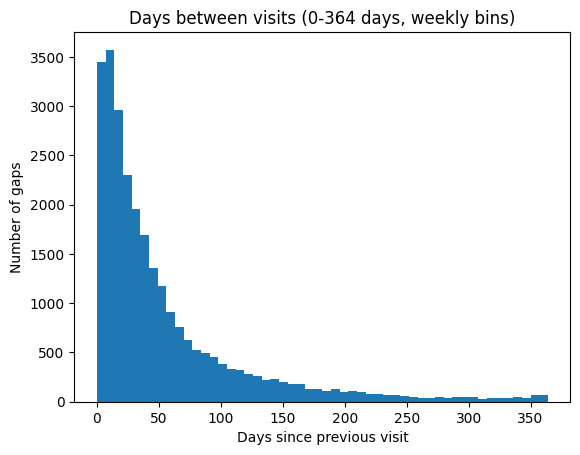

In [55]:
gaps.plot(kind='hist', bins=52, range=(0, 364), title='Days between visits (0-364 days, weekly bins)')
plt.xlabel('Days since previous visit')
plt.ylabel('Number of gaps')
print(gaps.quantile([0.5, 0.75, 0.9]))

In [56]:
own_gap = visits.groupby('Customer ID')['gap_days'].median().dropna()
print(own_gap.quantile([0.25, 0.5, 0.75]))

0.25     34.0
0.50     64.0
0.75    131.0
Name: gap_days, dtype: float64


#### Interpretation

Orders from same-day are counted as one visit. Out of 36,591 orders, 3,715 were placed on the same day as another order from the same customer, so they were merged into 32,876 visits. Two invoices on the same day are usually one shopping session, so if we keep them customers will look more frequent than they really are.

The median gap is 32 days, so a customer usually comes back after about one month. 75% of repeat visits happen within 70 days and 90% within 148 days.

So we call a customer "slipping away" after 150 days without buying, since only 1 in 10 visits comes after a longer gap than that. The data ends on 9 Dec 2011, so customers who bought in late November are not slipping yet, they just didn't have time to come back.

But one cutoff is not really fair for everyone. A quarter of customers usually come back within 34 days, while another quarter take more than 131 days. A fairer way is to call a customer slipping when they have been away more than 2 times their own usual gap, and use 150 days for customers who only have 1-2 visits.

By that, we should send a win-back offer to customers who haven't bought for 150 days, or sooner for the ones who usually buy every month.

### 5. Countries

#### Revenue per Country

Country
United Kingdom    85.3
EIRE               3.2
Netherlands        2.8
Germany            2.0
France             1.6
Australia          0.9
Spain              0.5
Switzerland        0.5
Sweden             0.4
Denmark            0.3
Name: Revenue, dtype: float64

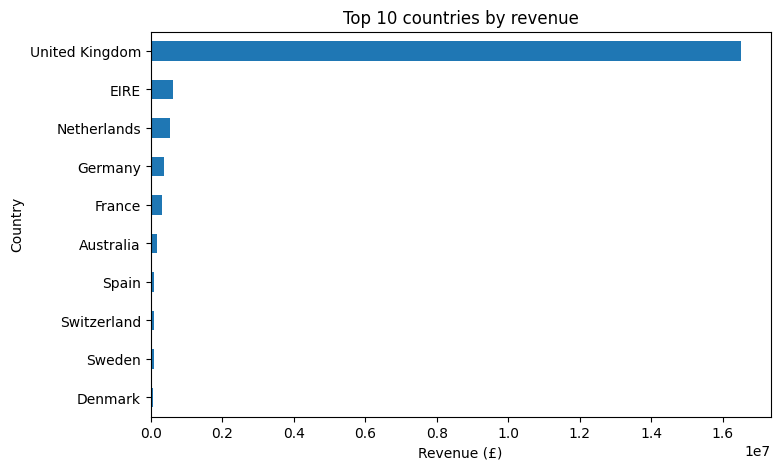

In [57]:
country_rev = sales.groupby('Country')['Revenue'].sum().sort_values(ascending=False)
country_rev.head(10).sort_values().plot(kind='barh', figsize=(8, 5), title='Top 10 countries by revenue')
plt.xlabel('Revenue (£)')
(country_rev / country_rev.sum() * 100).round(1).head(10)

#### Customers in More Than One Country

In [58]:
print("customers with 2+ countries:", (cust.groupby('Customer ID')['Country'].nunique() > 1).sum())
home = cust.groupby('Customer ID')['Country'].agg(lambda c: c.mode()[0])
cust['HomeCountry'] = cust['Customer ID'].map(home)
cust['Region'] = np.where(cust['HomeCountry'] == 'United Kingdom', 'United Kingdom', 'Rest of world')

customers with 2+ countries: 12


#### Behaviour per Group

In [59]:
def country_summary(col):
    t = cust.groupby(col).agg(customers=('Customer ID', 'nunique'),
                              orders=('Invoice', 'nunique'),
                              revenue=('Revenue', 'sum'))
    t['customer_share'] = (t['customers'] / t['customers'].sum() * 100).round(1)
    t['revenue_share'] = (t['revenue'] / t['revenue'].sum() * 100).round(1)
    t['avg_order'] = (t['revenue'] / t['orders']).round(1)
    t['orders_per_customer'] = (t['orders'] / t['customers']).round(1)
    return t.sort_values('revenue', ascending=False)

country_summary('Region')

,customers,orders,revenue,customer_share,revenue_share,avg_order,orders_per_customer
Region,,,,,,,
United Kingdom,5334,33358,1.400415e+07,91.1,83.4,419.8,6.3
Rest of world,518,3233,2.779809e+06,8.9,16.6,859.8,6.2


In [60]:
# Real countries with 20+ customers
by_country = country_summary('HomeCountry').drop(['Unspecified', 'European Community'], errors='ignore')
by_country[by_country['customers'] >= 20]

,customers,orders,revenue,customer_share,revenue_share,avg_order,orders_per_customer
HomeCountry,,,,,,,
United Kingdom,5334,33358,1.400415e+07,91.1,83.4,419.8,6.3
Netherlands,22,216,5.497734e+05,0.4,3.3,2545.2,9.8
Germany,106,752,3.831920e+05,1.8,2.3,509.6,7.1
France,93,592,3.096856e+05,1.6,1.8,523.1,6.4
Spain,35,137,9.639908e+04,0.6,0.6,703.6,3.9
Switzerland,22,90,9.554329e+04,0.4,0.6,1061.6,4.1
Belgium,28,144,5.678790e+04,0.5,0.3,394.4,5.1
Portugal,23,83,4.660952e+04,0.4,0.3,561.6,3.6


#### Interpretation

United Kingdom dominates the sales. It brings 85.3% of all revenue (83.4% of identified revenue) and 91.1% of the customers.

Outside UK, the biggest markets are EIRE (3.2%), Netherlands (2.8%), Germany (2.0%) and France (1.6%). EIRE is not in the table because it has less than 20 customers, and most of its revenue comes from 2 customers in our top 10 (14911 and 14156). Netherlands brings 3.3% of identified revenue with only 0.4% of the customers, but it's mostly from one customer (14646). Germany and France are close to their share of customers.

International customers buy differently. Their average order is £860, about 2 times the UK's £420 (even without the Dutch customer 14646 it's still about £730), but they order about as often (6.2 vs 6.3 orders per customer). So they make bigger orders, not fewer orders.

We will cluster all countries together. The segments are based on how customers buy, not where they are, and only 7 countries outside UK have 20 or more customers, which is too few to make their own segments. If we leave them out we also lose 16.6% of identified revenue and some of our top customers. After clustering, we can check how UK and international customers spread across the segments.

"Unspecified" and "European Community" are not real countries, so we left them out from the comparison. Only 12 customers (about 1 in 500) appear under more than one country, and we gave each of them their most common country. We only compared countries with at least 20 customers.

By that, we should keep UK as the main market, but also take care of the few big international buyers, because they make bigger orders.

### 6. Returns

#### Cleaning Returns with the Same Rule as Sales

In [61]:
rcode = returns['StockCode'].astype(str)
keep = ~(rcode.isin(NON_PRODUCT) | rcode.str.startswith('gift_')) & ~returns['Quantity'].abs().isin([80995, 74215])
returns = returns[keep].copy()
returns['ReturnValue'] = returns['Quantity'].abs() * returns['Price']
print("return rows:", len(returns))

return rows: 17913


#### Monthly Return Rate

overall return rate %: 2.4


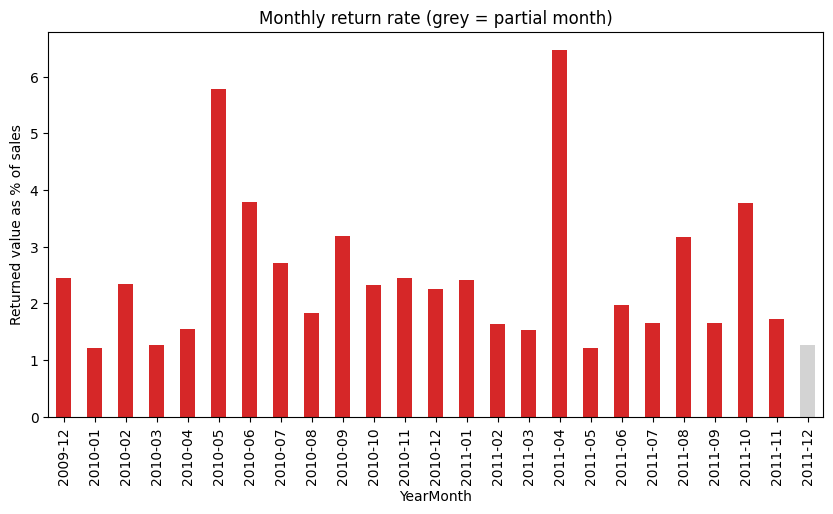

In [62]:
return_rate = (returns.groupby('YearMonth')['ReturnValue'].sum()
               / sales.groupby('YearMonth')['Revenue'].sum() * 100).fillna(0)
colors = ['lightgrey' if m == PARTIAL_MONTH else 'tab:red' for m in return_rate.index]
return_rate.plot(kind='bar', figsize=(10, 5), color=colors, title='Monthly return rate (grey = partial month)')
plt.ylabel('Returned value as % of sales')
print("overall return rate %:", round(returns['ReturnValue'].sum() / sales['Revenue'].sum() * 100, 1))

#### Returns per Customer

In [63]:
ret_cust = returns.dropna(subset=['Customer ID']).copy()
ret_cust['Customer ID'] = ret_cust['Customer ID'].astype(int).astype(str)
per_cust = spend[['spend']].copy()
per_cust['returned'] = ret_cust.groupby('Customer ID')['ReturnValue'].sum()
per_cust['returned'] = per_cust['returned'].fillna(0)
per_cust['return_rate'] = (per_cust['returned'] / per_cust['spend'] * 100).round(1)

r = per_cust['returned'].sort_values(ascending=False)
print("% of customers who ever returned:", round((per_cust['returned'] > 0).mean() * 100, 1))
print("% of returned value from top 5% of customers:", round(r.head(len(r) // 20).sum() / r.sum() * 100, 1))
print("customers with return rate above 100%:", (per_cust['return_rate'] > 100).sum())
per_cust.sort_values('spend', ascending=False).head(10)

% of customers who ever returned: 41.4
% of returned value from top 5% of customers: 76.4
customers with return rate above 100%: 3


,spend,returned,return_rate
Customer ID,,,
18102,580987.04,2578.40,0.4
14646,526751.52,3548.78,0.7
14156,303069.88,5294.87,1.7
14911,272252.79,13730.36,5.0
17450,244784.25,11140.34,4.6
13694,195640.69,5249.19,2.7
17511,172132.87,3628.43,2.1
16684,147142.77,5612.48,3.8
12415,144033.37,926.35,0.6


#### Most-Returned Products (by StockCode)

In [64]:
prod = sales.groupby('StockCode').agg(description=('Description', 'first'),
                                      orders=('Invoice', 'nunique'),
                                      sold_value=('Revenue', 'sum'))
prod['returned_value'] = returns.groupby('StockCode')['ReturnValue'].sum()
prod['returned_value'] = prod['returned_value'].fillna(0)
prod['return_rate'] = (prod['returned_value'] / prod['sold_value'] * 100).round(1)
enough = prod[prod['orders'] >= 50]
enough.sort_values('returned_value', ascending=False).head(5)

,description,orders,sold_value,returned_value,return_rate
StockCode,,,,,
22423,REGENCY CAKESTAND 3 TIER,3918,330590.32,16545.30,5.0
85123A,WHITE HANGING HEART T-LIGHT HOLDER,5365,257724.71,9387.10,3.6
71477,COLOUR GLASS. STAR T-LIGHT HOLDER,809,44680.75,7164.12,16.0
21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,613,25407.27,6614.37,26.0
79323W,WHITE CHERRY LIGHTS,349,18048.72,6421.10,35.6


In [65]:
enough.sort_values('return_rate', ascending=False).head(5)


,description,orders,sold_value,returned_value,return_rate
StockCode,,,,,
79323B,BLACK CHERRY LIGHTS,58,1565.70,1557.20,99.5
23113,PANTRY CHOPPING BOARD,57,5868.50,4803.06,81.8
79341,WILLOW BRANCH LIGHTS.,79,4423.69,2519.60,57.0
79323G,GOLD CHERRY LIGHTS,61,2007.88,1037.45,51.7
79323S,SILVER CHERRY LIGHTS,56,2084.32,976.80,46.9


#### Interpretation

Before checking returns, we removed the non-product codes with the same rule as sales, because fees and Manual credits would dominate the totals. We also removed the cancellations of the two bulk orders (80995 and 74215), because their sales were already dropped, so if we keep them it will count about £245k of returns for sales that don't exist.

Overall, only 2.4% of revenue gets returned. Most of the months stay between 1% and 2.5%, but there are spikes in May 2010 (about 5.8%) and April 2011 (about 6.5%), and smaller ones in June 2010 and October 2011 (about 3.8%).

41.4% of customers returned something at least once, but the returns are very concentrated. The top 5% of customers make 76.4% of all returned value. 3 customers have return rate above 100%, it's because they returned items that were bought before December 2009, which is not in the data, so it's not an error.

Our top spenders from step 3 are not heavy returners, all of them return 5% or less (the highest is 14911 with 5.0%). So we keep gross spend, since the reversed sales were already removed in cleaning and some returns are for purchases outside the data. The return rate can still be used later as its own feature.

The most returned products by value are big sellers like REGENCY CAKESTAND 3 TIER (5.0%) and WHITE HANGING HEART T-LIGHT HOLDER (3.6%), they are returned a lot only because they are sold a lot. The products with highest return rate are different, which are the cherry lights (black 99.5%, gold 51.7%, silver 46.9%, white 35.6%), the pantry chopping board (81.8%) and the willow branch lights (57.0%). These look like there's a real problem with the product, like quality, damage or wrong description, and they matter more for the business because a big part of their sales comes back.

By that, we should check the cherry lights and the chopping board first, and keep an eye on the few customers who make most of the returns.

### EDA Summary

These are the main things we found from the EDA:
- Sales peak from September to November, and 2011 is about flat compared to 2010 (+1.7% for Jan-Nov). The rise comes mostly from more customers, not bigger spending.
- New customers are going down (about 45% fewer in 2011), nearly 9 of 10 buyers each month are returning ones, and 27.7% only bought once.
- Spend is very skewed (mean £2,868 vs median £856), only 4.6% of customers bring 50% of the revenue and the top 10 bring about 16%.
- Customers usually come back after 32 days and 90% within 148 days, so 150 days is our cutoff for slipping away.
- UK brings 85.3% of revenue and 91.1% of customers. International customers make about 2 times bigger orders but order as often, so we keep all countries together.
- Only 2.4% of revenue is returned, but 76.4% of it comes from the top 5% of customers, and some products like the cherry lights have very high return rate.

So for the next part, we use recency, frequency and monetary (gross spend) with log and scaling because they are very skewed.

## 7. RFM Analysis

### RFM Table

In [66]:
snapshot = cust['InvoiceDate'].max() + pd.Timedelta(days=1)
print("Snapshot date: {}".format(snapshot.date()))

Snapshot date: 2011-12-10


In [67]:
rfm = spend[['orders', 'spend']].rename(columns={'orders': 'frequency', 'spend': 'monetary'})
rfm['recency'] = (snapshot - cust.groupby('Customer ID')['InvoiceDate'].max()).dt.days
rfm = rfm[['recency', 'frequency', 'monetary']]
rfm.describe().round(1)

,recency,frequency,monetary
count,5852.0,5852.0,5852.0
mean,200.3,6.3,2868.1
std,208.5,12.7,14100.4
min,1.0,1.0,2.9
25%,25.8,1.0,339.2
50%,95.0,3.0,855.6
75%,379.0,7.0,2236.9
max,739.0,373.0,580987.0


### RFM Scores

In [68]:
rfm['R'] = pd.qcut(rfm['recency'], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm['F'] = pd.qcut(rfm['frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm['M'] = pd.qcut(rfm['monetary'], 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm.head(5)

,recency,frequency,monetary,R,F,M
Customer ID,,,,,,
12346,529,2,169.36,1,2,1
12347,2,8,4921.53,5,4,5
12348,75,5,1658.40,3,4,4
12349,19,3,3678.69,5,3,5
12350,310,1,294.40,2,1,2


### Distribution

array([[<Axes: title={'center': 'recency'}>,
        <Axes: title={'center': 'frequency'}>,
        <Axes: title={'center': 'monetary'}>]], dtype=object)

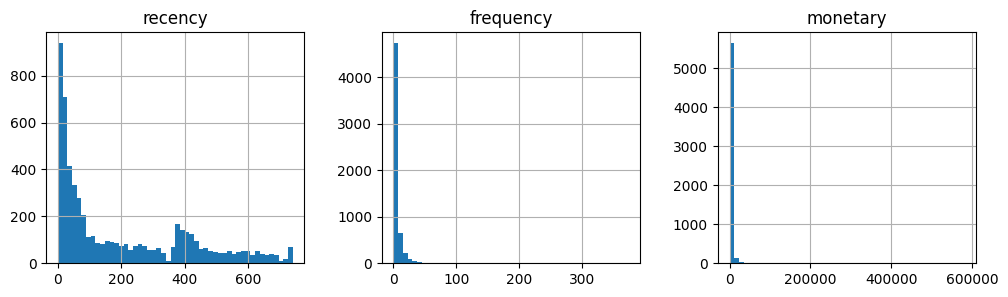

In [69]:
rfm[['recency', 'frequency', 'monetary']].hist(bins=50, figsize=(12, 3), layout=(1, 3))

In [70]:
print("There are {}% customers slipping away (more than 150 days)".format(round((rfm['recency'] > 150).mean() * 100, 1)))

There are 43.8% customers slipping away (more than 150 days)


In [71]:
rfm[['recency', 'frequency', 'monetary']].corr().round(2)

,recency,frequency,monetary
recency,1.00,-0.26,-0.12
frequency,-0.26,1.00,0.63
monetary,-0.12,0.63,1.00


#### Interpretation

The snapshot date is 10 Dec 2011, one day after the last purchase. Recency is the days since last purchase, frequency is the number of orders (same as step 3), and monetary is the gross spend (from step 6).

All three are very skewed. The mean recency is 200 days but the median is only 95, the mean frequency is 6.3 orders but the median is 3, and the mean spend is £2,868 while the median is £856 (the max is £580,987). Because of that, we will log and scale the RFM values before K-Means, so the few huge customers don't take over the clusters. For the scores, each one is split into 5 equal groups (5 is the best), and frequency is ranked first because a lot of customers only have 1 order.

43.8% of customers haven't bought for more than 150 days, so they are slipping away based on our cutoff from step 4. A quarter of all customers even haven't bought for more than a year (379 days).

Frequency and monetary are quite related (0.63), customers who order more also spend more, so they partly tell the same thing. Recency is only weakly related to both (-0.26 and -0.12), so it gives different information.

By that, we should focus on winning back the slipping customers, since they are almost half of our customers.

## 8. Rule-based Segments

In [72]:
conditions = [
    (rfm['R'] >= 4) & (rfm['F'] >= 4) & (rfm['M'] >= 4),
    (rfm['recency'] <= 150) & (rfm['F'] >= 4),
    (rfm['recency'] <= 150) & (rfm['frequency'] == 1),
    (rfm['recency'] > 150) & ((rfm['F'] >= 3) | (rfm['M'] >= 4)),
    rfm['recency'] > 150,
]
labels = ['Champions', 'Loyal', 'New', 'At Risk', 'Lost']
rfm['Segment'] = np.select(conditions, labels, default='Need Attention')
rfm['Segment'].value_counts()

Segment
Lost              1519
Champions         1291
At Risk           1046
Need Attention     949
Loyal              604
New                443
Name: count, dtype: int64

In [73]:
segments = rfm.groupby('Segment').agg(customers=('recency', 'size'),
                                     recency=('recency', 'median'),
                                     frequency=('frequency', 'median'),
                                     monetary=('monetary', 'median'),
                                     revenue=('monetary', 'sum'))
segments['customer_share'] = (segments['customers'] / segments['customers'].sum() * 100).round(1)
segments['revenue_share'] = (segments['revenue'] / segments['revenue'].sum() * 100).round(1)
segments.sort_values('revenue', ascending=False)

,customers,recency,frequency,monetary,revenue,customer_share,revenue_share
Segment,,,,,,,
Champions,1291,16.0,11.0,3900.830,1.165285e+07,22.1,69.4
At Risk,1046,337.5,4.0,1101.705,1.944375e+06,17.9,11.6
Loyal,604,72.0,6.0,1606.460,1.587445e+06,10.3,9.5
Need Attention,949,36.0,3.0,746.360,9.373273e+05,16.2,5.6
Lost,1519,428.0,1.0,259.680,4.922090e+05,26.0,2.9
New,443,53.0,1.0,256.380,1.697531e+05,7.6,1.0


<Axes: title={'center': 'Customer share vs revenue share per segment'}, ylabel='Segment'>

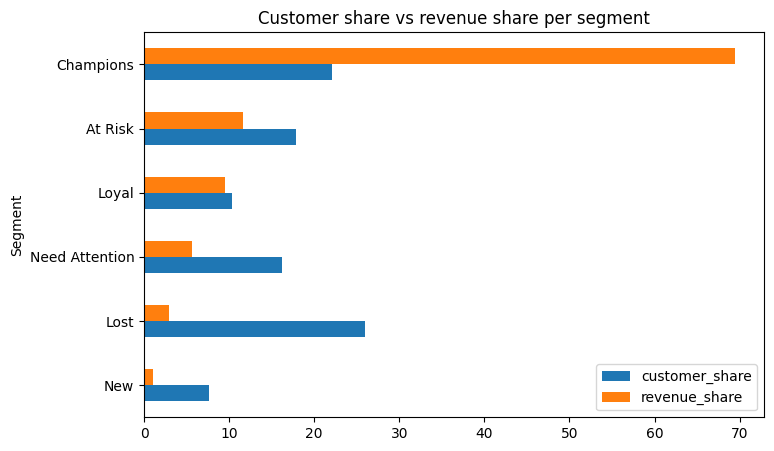

In [74]:
segments[['customer_share', 'revenue_share']].sort_values('revenue_share').plot(kind='barh', figsize=(8, 5), title='Customer share vs revenue share per segment')

#### Interpretation

We made the rule-based segments first because they are easy to explain, and later we can compare them with the K-Means clusters.

Champions bring most of the money. They are 22.1% of customers but 69.4% of the revenue, they bought recently (median 16 days), order often (11 orders) and spend about £3,900. Loyal customers are 10.3% of customers and bring 9.5% of the revenue.

At Risk is the group that worth to win back. They are 17.9% of customers and still brought 11.6% of the revenue (about £1.9M), with median of 4 orders and £1,102 spend, but their last purchase was about 338 days ago. Together with Lost, they are 43.8% of customers, same as the slipping customers in step 7.

Lost customers are the biggest group (26.0%) but only bring 2.9% of the revenue. Most of them only bought once (median £260), and the typical one hasn't bought for more than a year (428 days). New customers are 7.6% with only 1 order so far, and Need Attention (16.2%) are active but in the middle.

By that, we should keep the Champions happy, win back the At Risk customers before they become Lost, and not spend too much on the Lost ones.

## 9. K-Means Clustering

In [75]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

### Scaling

In [76]:
rfm_log = np.log1p(rfm[['recency', 'frequency', 'monetary']])
X = StandardScaler().fit_transform(rfm_log)

### Choosing k

In [77]:
inertia = []
silhouette = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    pred = km.fit_predict(X)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X, pred, sample_size=3000, random_state=42))

Text(0.5, 0, 'k')

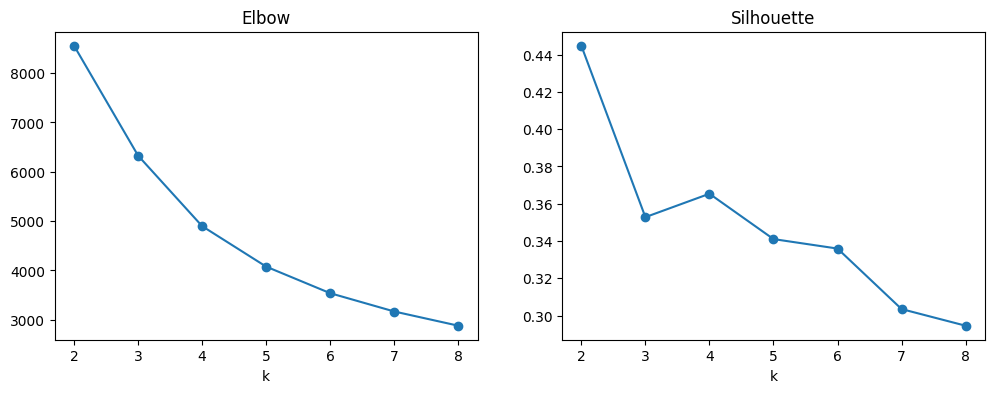

In [78]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(2, 9), inertia, marker='o')
ax[0].set_title('Elbow')
ax[0].set_xlabel('k')
ax[1].plot(range(2, 9), silhouette, marker='o')
ax[1].set_title('Silhouette')
ax[1].set_xlabel('k')

### Clusters

In [79]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm['Cluster'] = kmeans.fit_predict(X)
rfm['Cluster'].value_counts()

Cluster
3    1962
0    1455
1    1249
2    1186
Name: count, dtype: int64

In [80]:
clusters = rfm.groupby('Cluster').agg(customers=('recency', 'size'),
                                     recency=('recency', 'median'),
                                     frequency=('frequency', 'median'),
                                     monetary=('monetary', 'median'),
                                     revenue=('monetary', 'sum'))
clusters['customer_share'] = (clusters['customers'] / clusters['customers'].sum() * 100).round(1)
clusters['revenue_share'] = (clusters['revenue'] / clusters['revenue'].sum() * 100).round(1)
clusters.sort_values('revenue', ascending=False)

,customers,recency,frequency,monetary,revenue,customer_share,revenue_share
Cluster,,,,,,,
2,1186,17.0,13.0,4898.690,1.236716e+07,20.3,73.7
0,1455,184.0,4.0,1449.140,2.749743e+06,24.9,16.4
1,1249,24.0,3.0,716.570,1.048339e+06,21.3,6.2
3,1962,401.0,1.0,273.285,6.187138e+05,33.5,3.7


## 10. Compare, Validate and Name Segments

In [81]:
pd.crosstab(rfm['Cluster'], rfm['Segment'])

Segment,At Risk,Champions,Lost,Loyal,Need Attention,New
Cluster,,,,,,
0,801,98,43,327,179,7
1,0,133,0,174,706,236
2,21,1060,0,101,4,0
3,224,0,1476,2,60,200


#### Interpretation

We log and scale recency, frequency and monetary before K-Means, because they are very skewed and in different scales. For k, the silhouette is highest at k=2 (about 0.44), but 2 groups only split active and inactive customers, which is too simple for marketing. k=4 has the next best silhouette (about 0.37, higher than k=3 and k=5) and the elbow starts to flatten after 4, so we chose 4 clusters.

Cluster 2 is the best customers. They are 20.3% of customers but bring 73.7% of the revenue, they bought recently (median 17 days), order often (13 orders) and spend about £4,900.

Cluster 0 is the regular customers that are slipping away. They are 24.9% of customers and bring 16.4% of the revenue, with 4 orders and £1,449 spend, but their last purchase was about 184 days ago.

Cluster 1 is active but small buyers. They bought recently (24 days) but only have 3 orders and £717 spend, so 21.3% of customers only bring 6.2% of the revenue.

Cluster 3 is lost one-time buyers. They are the biggest group (33.5%) but only bring 3.7% of the revenue. The typical one only bought once (£273) and hasn't come back for more than a year (401 days).

The clusters mostly agree with our rule-based segments. 82% of Champions are in cluster 2, 77% of At Risk are in cluster 0, and 97% of Lost are in cluster 3. Cluster 1 is mostly Need Attention and New customers.

By that, we name them Best Customers, Slipping Regulars, Active Small Buyers and Lost One-timers, and we treat each of them differently in the recommendations.

### Naming the Clusters

In [82]:
cluster_names = {2: 'Best Customers', 0: 'Slipping Regulars', 1: 'Active Small Buyers', 3: 'Lost One-timers'}
rfm['ClusterName'] = rfm['Cluster'].map(cluster_names)
pd.crosstab(rfm['ClusterName'], rfm['Segment'])

Segment,At Risk,Champions,Lost,Loyal,Need Attention,New
ClusterName,,,,,,
Active Small Buyers,0,133,0,174,706,236
Best Customers,21,1060,0,101,4,0
Lost One-timers,224,0,1476,2,60,200
Slipping Regulars,801,98,43,327,179,7


## 11. Recommendations

In [83]:
summary = rfm.groupby('ClusterName').agg(customers=('recency', 'size'),
                                         recency=('recency', 'median'),
                                         frequency=('frequency', 'median'),
                                         monetary=('monetary', 'median'),
                                         revenue=('monetary', 'sum'))
summary['customer_share'] = (summary['customers'] / summary['customers'].sum() * 100).round(1)
summary['revenue_share'] = (summary['revenue'] / summary['revenue'].sum() * 100).round(1)
summary.sort_values('revenue', ascending=False)

,customers,recency,frequency,monetary,revenue,customer_share,revenue_share
ClusterName,,,,,,,
Best Customers,1186,17.0,13.0,4898.690,1.236716e+07,20.3,73.7
Slipping Regulars,1455,184.0,4.0,1449.140,2.749743e+06,24.9,16.4
Active Small Buyers,1249,24.0,3.0,716.570,1.048339e+06,21.3,6.2
Lost One-timers,1962,401.0,1.0,273.285,6.187138e+05,33.5,3.7


<Axes: title={'center': 'Customer share vs revenue share per cluster'}, ylabel='ClusterName'>

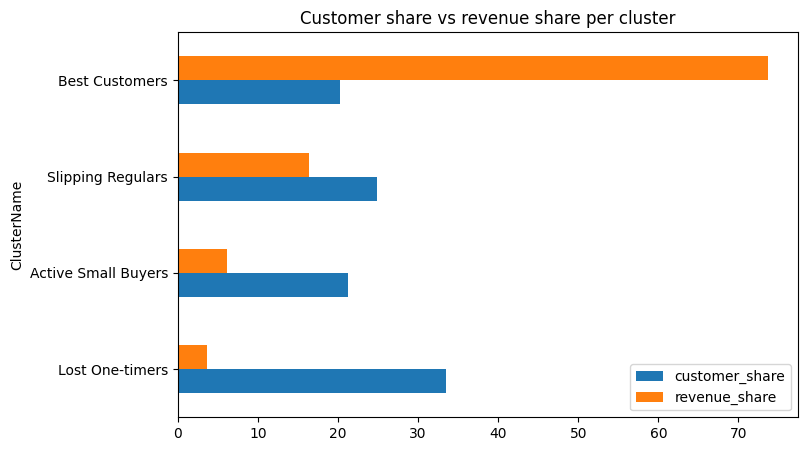

In [84]:
summary[['customer_share', 'revenue_share']].sort_values('revenue_share').plot(kind='barh', figsize=(8, 5), title='Customer share vs revenue share per cluster')

#### What We Should Do

Each group needs different treatment, so the marketing budget shouldn't be spread equally.

- Best Customers (20.3% of customers, 73.7% of revenue): keep them happy first. Give them personal contact, priority service and early access to new stock before the September to November peak. They already buy often, so they don't really need big discounts.
- Slipping Regulars (24.9% of customers, 16.4% of revenue): win them back before they become lost. Their last purchase was about 184 days ago, so we should send a reminder or personal offer once a customer passes 150 days (or 2 times of their own usual gap), and do it around August before the autumn peak.
- Active Small Buyers (21.3% of customers, 6.2% of revenue): they bought recently but in small amount, so we should grow their orders with bundles, free postage above minimum order, and follow-up after the first order to make them become regulars.
- Lost One-timers (33.5% of customers, 3.7% of revenue): only send one cheap automatic win-back email, and don't spend more budget on them if they don't come back.

Beside the segments, we should also check the products with high return rate (the cherry lights and the pantry chopping board), and keep the big international buyers in the Best Customers treatment because they make bigger orders.

By that, most of the budget should go to keeping the Best Customers and winning back the Slipping Regulars, because together they bring 90.1% of the revenue.

## 12. Reflection

We chose RFM with K-Means because it's simple, easy to explain to non-technical people, and answers which customers to spend the budget on. We made rule-based segments first to check if the clusters make sense, and both mostly agree.

What went well:
- RFM only needs transaction data the retailer already has, and the three numbers are easy to understand.
- The cleaning decisions are written step by step, so the numbers can be reproduced.
- The clusters are clear and match the rule-based segments (82% of Champions in Best Customers, 97% of Lost in Lost One-timers).

What's not good yet:
- About 23% of sales have no Customer ID, so our segments only describe identified customers.
- RFM only looks at the past and doesn't use product, country or returns, and the 150-day cutoff is the same for everyone.
- The silhouette is only moderate (about 0.37), so the clusters are not very sharp, and the cluster numbers can change if the data is updated.
- The data starts in Dec 2009 and stops on 9 Dec 2011, so customers at the edges look newer or more slipping than they really are.

What we could do next:
- Use each customer's own buying gap for slipping away.
- Add features like return rate, average order value or country, and compare with other methods like Gaussian Mixture or hierarchical clustering.

## Use of Generative AI 

- Some help on building the code
- Helping on correction of interpretation and code 
- Create draft points of summary
- Help on converting essential information from notebook to report like the visualization.